# Transformer reconstruction model: Dataset 2 scores

Scores Dataset 2 with the frozen 12-hour baseline model (the best model from the ablation study) and its frozen calibration, and summarizes the result. Nothing is trained or recalibrated here.

What it needs:

| File | What it is |
|---|---|
| `best_model.pt` | Model weights and settings from `train_batadal_recon_model.py` |
| `calibration.pt` | Frozen thresholds and per-sensor references from `calibrate_recon_model.py` |
| `data/processed/` | The processed files from `Pipeline.ipynb` |
| `model.py`, `layers.py`, `batadal_dataset.py`, `evaluate_recon_model.py` | The project code, in `CODE_DIR` |

What it produces, in `OUT_DIR`:

- the Dataset 2 metrics, per-attack results and plots, from the same code as `evaluate_recon_model.py`
- a summary of the scores: headline figures, hour counts, each attack, each false alarm and the score distribution, saved as `dataset2_summary.json`, `attack_summary.csv` and `false_alarm_summary.csv`

## Settings

In [ ]:
from pathlib import Path

CODE_DIR = Path("..")                                     # models/Transformer
DATA_DIR = Path("../../../data/processed")                # repo root / data / processed
SOURCE_CHECKPOINT = Path("Model Weights/best_model.pt")   # the full checkpoint
CHECKPOINT = Path("Model Weights/best_model.pt")          # the file scored with (a new name makes a slim copy in step 1)
CALIBRATION = Path("Model Weights/calibration/calibration.pt")
OUT_DIR = Path("inference_results")

SCORE = "topk_percentile"   # the score whose alarms are reported (the proposal's)
GRACE_HOURS = 3             # must match the setting the calibration was evaluated with
BATCH_SIZE = 128
DEVICE = "cpu"  # Use "cuda" if you have a cuda-enabled GPU and installed it's dependencies.

## 1. Slim checkpoint (optional, once)

`best_model.pt` also holds the optimizer state, about two thirds of the file. Scoring needs only the weights and the settings. When `CHECKPOINT` names a file that does not exist yet, this cell writes that smaller copy; when it names `best_model.pt` itself, the full file is used as it is.

In [44]:
import torch

if not CHECKPOINT.exists():
    full = torch.load(SOURCE_CHECKPOINT, map_location="cpu")
    slim = {key: value for key, value in full.items() if key not in ("optimizer", "history")}
    CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)
    torch.save(slim, CHECKPOINT)
    print(f"{SOURCE_CHECKPOINT.stat().st_size / 1e6:.2f} MB -> {CHECKPOINT.stat().st_size / 1e6:.2f} MB")
else:
    print(f"Using {CHECKPOINT} ({CHECKPOINT.stat().st_size / 1e6:.2f} MB)")

Using Model Weights/best_model.pt (2.43 MB)


## 2. Load the project code, the model and the calibration

In [45]:
import sys
sys.path.insert(0, str(CODE_DIR.resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from model import Transformer_Recon_Model
from batadal_dataset import build_dataloaders, DATASET2_FILE
from evaluate_recon_model import (
    SCORE_TYPES, load_model, load_calibration, scaler_matches,
    sensor_errors, hourly_scores, run_evaluation)

assert SCORE in SCORE_TYPES, f"SCORE must be one of {SCORE_TYPES}"
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [46]:
ok, ckpt = load_model(CHECKPOINT)
assert ok, f"Could not load {CHECKPOINT}"

# Older checkpoints used num_encodings / bottleneck_dim for the bottleneck.
num_latent_tokens = ckpt.get("num_latent_tokens", ckpt.get("num_encodings"))
latent_dim = ckpt.get("latent_dim", ckpt.get("bottleneck_dim", 16))

model = Transformer_Recon_Model(
    in_dim=ckpt["in_dim"],
    embedding_dim=ckpt["embedding_dim"],
    hidden_dim=ckpt["hidden_dim"],
    num_heads=ckpt["num_heads"],
    num_latent_tokens=num_latent_tokens,
    latent_dim=latent_dim,
    num_window=ckpt["window"],
    num_enc_blocks=ckpt["num_enc_blocks"],
    num_dec_blocks=ckpt["num_dec_blocks"],
    dropout=ckpt["dropout"],
    activation_type=ckpt["activation_type"])
model.load_state_dict(ckpt["model"])
model = model.to(DEVICE).eval()

calibration, saved = load_calibration(CALIBRATION)
window = ckpt["window"]
if saved["window"] != window or saved["feature_names"] != ckpt["feature_names"]:
    raise ValueError("The calibration was made for a different model")

print(f"Window: {window} h | latent: {num_latent_tokens} tokens x {latent_dim} | "
      f"parameters: {sum(p.numel() for p in model.parameters()):,} | device: {DEVICE}")
print(f"Checkpoint step: {ckpt['curr_global_steps']:,} | seed: {ckpt.get('seed')}")
print(f"Calibration: top-k {calibration['top_k']}, merge gap {calibration['merge_gap_hours']} h, "
      f"budget {calibration['max_episodes_per_week']:g} episode/week and "
      f"{calibration['max_alarm_fraction']:.0%} of hours")
print("Thresholds:", {s: round(t, 6) for s, t in calibration["thresholds"].items()})

Window: 12 h | latent: 4 tokens x 16 | parameters: 192,820 | device: cpu
Checkpoint step: 25,000 | seed: 0
Calibration: top-k 3, merge gap 2 h, budget 1 episode/week and 1% of hours
Thresholds: {'topk_percentile': 0.998448, 'mean': 0.001791, 'topk_ratio': 32.761668}


## 3. Load the data

In [47]:
loaders, scaler, info = build_dataloaders(
    str(DATA_DIR),
    str(DATA_DIR / DATASET2_FILE),
    window=window,
    batch_size=BATCH_SIZE)

if info["feature_names"] != ckpt["feature_names"]:
    raise ValueError("The data's features differ from the model's")
if not scaler_matches(scaler, ckpt):
    raise ValueError("The data's scaler differs from the model's: is this the same processed data?")

for name, loader in loaders.items():
    print(f"{name:6s} {len(loader.dataset):6,} scored hours")

train   5,245 scored hours
val     1,717 scored hours
calib   1,718 scored hours
dev     4,166 scored hours


/home/vinlaptop/Desktop/ML_Projects/myenv/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator MinMaxScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 4. Score Dataset 2

Each hour is scored from the 12-hour window that ends at it. The thresholds come from `calibration.pt` and are not changed. `run_evaluation` is the same function `evaluate_recon_model.py` uses, so `metrics.json`, `per_attack.csv`, `hourly_scores.csv` and the plots match the script's.

In [48]:
from evaluate_recon_model import episode_spans, to_ratios

dev_errors, dev_rows = sensor_errors(model=model, dataloader=loaders["dev"], device=DEVICE)
dev_when = pd.to_datetime(info["dev"]["datetime"][dev_rows])
dev_labels = info["dev"]["labels"][dev_rows]
dev_attack_id = info["dev"]["attack_id"][dev_rows]

flat = run_evaluation(
    calibration=calibration,
    dev_errors=dev_errors,
    dev_when=dev_when.to_numpy(),
    dev_labels=dev_labels,
    dev_attack_id=dev_attack_id,
    feature_names=info["feature_names"],
    out_dir=str(OUT_DIR),
    grace_hours=GRACE_HOURS,
    log=lambda *args: None)   # the summary below replaces the printed table

reference = calibration["reference"]
top_k = calibration["top_k"]
threshold = calibration["thresholds"][SCORE]
merge_gap = calibration["merge_gap_hours"]
feature_names = info["feature_names"]

scores = hourly_scores(dev_errors, reference, SCORE, top_k)
alarms = scores > threshold
ratios = to_ratios(dev_errors, reference["calib_q99"])   # each sensor's error / its normal 99th percentile

# Hours left out of the hour-by-hour figures: the grace hours after each attack.
grace = np.zeros(len(scores), dtype=bool)
for a in np.unique(dev_attack_id[dev_attack_id > 0]):
    end = np.flatnonzero(dev_attack_id == a)[-1] + 1
    grace[end:end + GRACE_HOURS] = True
grace &= dev_attack_id == 0
is_attack = dev_labels == 1
is_clean = (dev_labels == 0) & ~grace

def top_sensors(mask, n=3):
    mean_ratio = ratios[mask].mean(axis=0)
    order = np.argsort(mean_ratio)[::-1][:n]
    return ", ".join(f"{feature_names[j]} ({mean_ratio[j]:.1f}x)" for j in order)

print(f"Scored {len(scores):,} hours from {dev_when[0]} to {dev_when[-1]}; "
      f"the first {window - 1} hours of Dataset 2 have no score.")

Scored 4,166 hours from 2016-07-04 11:00:00 to 2016-12-25 00:00:00; the first 11 hours of Dataset 2 have no score.


## 5. Summary of the scores

### Headline

The score that raises the alarms is `SCORE`. The other two scores are shown for comparison; each has its own frozen threshold.

In [49]:
m = {key[len(SCORE) + 1:]: value for key, value in flat.items() if key.startswith(SCORE + "_")}
budget = (f"{calibration['max_episodes_per_week']:g} episode per week and "
          f"{calibration['max_alarm_fraction']:.0%} of clean hours")
print(f"{SCORE}: {m['attacks_detected']} of {m['attacks_total']} attacks detected"
      + (f" (missed: {m['missed_attacks']})" if m["missed_attacks"] else "")
      + f", mean delay {m['mean_delay_hours']:.1f} h, PR-AUC {m['pr_auc']:.3f}.")
print(f"False alarms: {m['false_alarm_episodes_per_week']:.2f} episodes per week and "
      f"{m['clean_hours_under_alarm']:.2%} of clean hours, against a budget of {budget}: "
      f"{'inside' if m['dev_in_budget'] else 'OUTSIDE'} the budget.")

rows = {
    "Attacks detected (of 7)": "attacks_detected",
    "Missed attacks": "missed_attacks",
    "Mean delay (h)": "mean_delay_hours",
    "Median delay (h)": "median_delay_hours",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "pr_auc",
    "S-score": "s_score",
    "False-alarm episodes per week": "false_alarm_episodes_per_week",
    "Clean hours under alarm": "clean_hours_under_alarm",
    "Inside budget on Dataset 2": "dev_in_budget",
    "Threshold": "threshold"}
headline = pd.DataFrame({s: [flat.get(f"{s}_{key}") for key in rows.values()] for s in SCORE_TYPES},
                        index=list(rows))
headline.loc["Missed attacks"] = headline.loc["Missed attacks"].replace("", "none")
display(headline)

topk_percentile: 7 of 7 attacks detected, mean delay 1.7 h, PR-AUC 0.792.
False alarms: 1.15 episodes per week and 0.88% of clean hours, against a budget of 1 episode per week and 1% of clean hours: OUTSIDE the budget.


,topk_percentile,mean,topk_ratio
Attacks detected (of 7),7,7,7
Missed attacks,none,none,none
Mean delay (h),1.714286,1.571429,9.857143
Median delay (h),0.0,0.0,2.0
Precision,0.906433,0.890374,0.83871
Recall,0.630081,0.676829,0.422764
F1,0.743405,0.769053,0.562162
ROC-AUC,0.919302,0.926829,0.91829
PR-AUC,0.79152,0.823343,0.75828
S-score,0.894611,0.908595,0.800917


### Hours

In [50]:
tp = int((alarms & is_attack).sum())
fn = int((~alarms & is_attack).sum())
fp = int((alarms & is_clean).sum())
tn = int((~alarms & is_clean).sum())

hours = pd.DataFrame(
    [[tp, fn, tp + fn], [fp, tn, fp + tn], [tp + fp, fn + tn, tp + fn + fp + tn]],
    index=["Attack hours", "Clean hours", "Total"],
    columns=["Alarm", "No alarm", "Total"])
display(hours)
print(f"{int(grace.sum())} grace hours after attacks are left out. "
      f"{tp / (tp + fp):.0%} of alarms fall inside an attack; "
      f"{tp / (tp + fn):.0%} of attack hours are under alarm.")

,Alarm,No alarm,Total
Attack hours,310,182,492
Clean hours,32,3621,3653
Total,342,3803,4145


21 grace hours after attacks are left out. 91% of alarms fall inside an attack; 63% of attack hours are under alarm.


### Each attack

Delay is counted from the attack's real start. *Hours under alarm* is the share of the attack's hours with an alarm. *Main sensors* are the three with the highest mean error during the attack, as a multiple of their normal 99th percentile.

In [51]:
per_attack = pd.read_csv(OUT_DIR / "per_attack.csv")
attack_rows = []
for _, a in per_attack.iterrows():
    inside = dev_attack_id == a["attack"]
    attack_rows.append({
        "attack": int(a["attack"]),
        "start": a["real_start"],
        "hours": int(a["hours"]),
        "detected": bool(a[f"{SCORE}_detected"]),
        "delay (h)": a[f"{SCORE}_delay_hours"],
        "hours under alarm": f"{alarms[inside].mean():.0%}",
        "peak score": round(float(scores[inside].max()), 4),
        "main sensors": top_sensors(inside)})
attack_summary = pd.DataFrame(attack_rows)
attack_summary.to_csv(OUT_DIR / "attack_summary.csv", index=False)
display(attack_summary)

,attack,start,hours,detected,delay (h),hours under alarm,peak score,main sensors
0,1,2016-09-13 23,50,True,0,90%,1.0,"S_PU11 (12423247.0x), F_PU11 (4087938.2x), S_P..."
1,2,2016-09-26 11,24,True,0,79%,1.0,"P_J307 (27.6x), P_J302 (25.9x), P_J317 (15.2x)"
2,3,2016-10-09 09,60,True,0,45%,1.0,"S_PU4 (18188.9x), S_PU2 (5326.4x), F_PU2 (105.0x)"
3,4,2016-10-29 19,94,True,0,90%,1.0,"S_PU4 (195401.0x), S_V2 (3990.5x), S_PU2 (1438..."
4,5,2016-11-26 17,60,True,5,55%,1.0,"S_PU6 (43682.2x), F_PU6 (34021.5x), S_PU7 (125..."
5,6,2016-12-06 07,94,True,2,81%,1.0,"S_PU4 (238629.0x), S_PU6 (158781.4x), F_PU6 (1..."
6,7,2016-12-14 15,110,True,5,23%,1.0,"S_PU11 (389564.3x), S_PU4 (235918.7x), F_PU11 ..."


### False alarms

Alarm episodes outside every attack window, longest first, with the sensors that drove them.

In [52]:
false_rows = []
for first, last in episode_spans(alarms & is_clean, merge_gap):
    span = np.zeros(len(scores), dtype=bool)
    span[first:last + 1] = True
    false_rows.append({
        "start": dev_when[first],
        "hours": last - first + 1,
        "alarm hours": int((alarms & span).sum()),
        "peak score": round(float(scores[span].max()), 4),
        "hours to next attack start": next(
            (int((dev_when[i] - dev_when[last]) / pd.Timedelta(hours=1))
             for i in range(last + 1, len(scores)) if is_attack[i] and not is_attack[i - 1]), None),
        "main sensors": top_sensors(span & alarms)})
false_summary = pd.DataFrame(false_rows).sort_values(["hours", "peak score"], ascending=False)
false_summary.to_csv(OUT_DIR / "false_alarm_summary.csv", index=False)
print(f"{len(false_summary)} false-alarm episodes, {int(fp)} alarm hours. "
      f"{(false_summary['hours to next attack start'] <= 24).sum()} end within 24 h of an attack's start.")
display(false_summary.head(10))

sensor_counts = pd.Series(
    [s.split(" (")[0] for text in false_summary["main sensors"] for s in text.split(", ")]).value_counts()
print("Sensors most often behind false alarms:")
display(sensor_counts.head(8).rename("episodes"))

25 false-alarm episodes, 32 alarm hours. 5 end within 24 h of an attack's start.


,start,hours,alarm hours,peak score,hours to next attack start,main sensors
11,2016-10-12 00:00:00,5,4,0.9996,423.0,"L_T2 (4.1x), L_T1 (3.1x), P_J289 (2.6x)"
1,2016-07-07 00:00:00,2,2,1.0000,1654.0,"S_PU6 (226871.9x), F_PU6 (96303.3x), F_PU7 (11..."
4,2016-07-26 04:00:00,2,2,1.0000,1194.0,"S_PU2 (2170.1x), S_PU6 (333.5x), F_PU6 (96.4x)"
24,2016-12-24 23:00:00,2,2,1.0000,NaN,"S_PU6 (226856.1x), F_PU6 (115308.7x), F_PU7 (1..."
20,2016-11-13 20:00:00,2,2,0.9990,308.0,"F_PU6 (81.7x), F_PU7 (14.8x), S_PU6 (4.5x)"
2,2016-07-20 15:00:00,1,1,1.0000,1328.0,"S_PU7 (28881.0x), F_PU7 (514.4x), P_J415 (13.3x)"
9,2016-09-26 10:00:00,1,1,1.0000,1.0,"S_PU10 (54140.5x), F_PU10 (459.9x), L_T7 (3.0x)"
16,2016-10-27 01:00:00,1,1,1.0000,66.0,"S_PU2 (338.6x), P_J280 (106.6x), F_PU2 (25.9x)"
17,2016-10-29 18:00:00,1,1,1.0000,1.0,"L_T1 (8.0x), F_PU2 (7.0x), F_PU1 (7.0x)"
18,2016-11-06 17:00:00,1,1,1.0000,480.0,"S_PU8 (63.4x), F_PU8 (5.5x), L_T5 (3.6x)"


Sensors most often behind false alarms:


P_J289    6
P_J300    6
P_J307    5
S_PU6     4
F_PU6     4
F_PU7     4
S_PU7     4
F_V2      4
Name: episodes, dtype: int64

### Score distribution

How clean and attack hours fall against the threshold. The percentile score tops out at 1, so it is drawn as its distance from 1 on a log scale, which spreads out the hours near the top: 1 on the axis is a score of 0.9, 2 is 0.99, 3 is 0.999, and hours at the ceiling of exactly 1 are drawn at 6.

In [53]:
def spread(values):
    return -np.log10(np.clip(1 - values, 1e-6, None)) if SCORE == "topk_percentile" else values

bins = np.linspace(spread(scores).min(), spread(scores).max(), 60)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(spread(scores[is_clean]), bins=bins, color="0.6", alpha=0.8, label=f"clean hours ({is_clean.sum():,})")
ax.hist(spread(scores[is_attack]), bins=bins, color="#2a78d6", alpha=0.8, label=f"attack hours ({is_attack.sum():,})")
ax.axvline(spread(np.array([threshold]))[0], color="black", ls="--", lw=1, label="threshold")
ax.set_yscale("log")
ax.set_xlabel(f"{SCORE}" + (" as -log10(1 - score)" if SCORE == "topk_percentile" else ""))
ax.set_ylabel("hours")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR / f"score_distribution_{SCORE}.png", dpi=150)
plt.show()

quantiles = pd.DataFrame({
    "clean hours": np.quantile(scores[is_clean], [0.5, 0.9, 0.99, 1.0]),
    "attack hours": np.quantile(scores[is_attack], [0.5, 0.9, 0.99, 1.0])},
    index=["median", "90th percentile", "99th percentile", "max"])
display(quantiles.round(5))
print(f"Attack hours at the score's ceiling of 1: {(scores[is_attack] >= 1).mean():.0%}; "
      f"clean hours: {(scores[is_clean] >= 1).mean():.1%}.")

,clean hours,attack hours
median,0.94199,1.0
90th percentile,0.98502,1.0
99th percentile,0.99845,1.0
max,1.00000,1.0


Attack hours at the score's ceiling of 1: 51%; clean hours: 0.3%.


### Plots from the evaluation

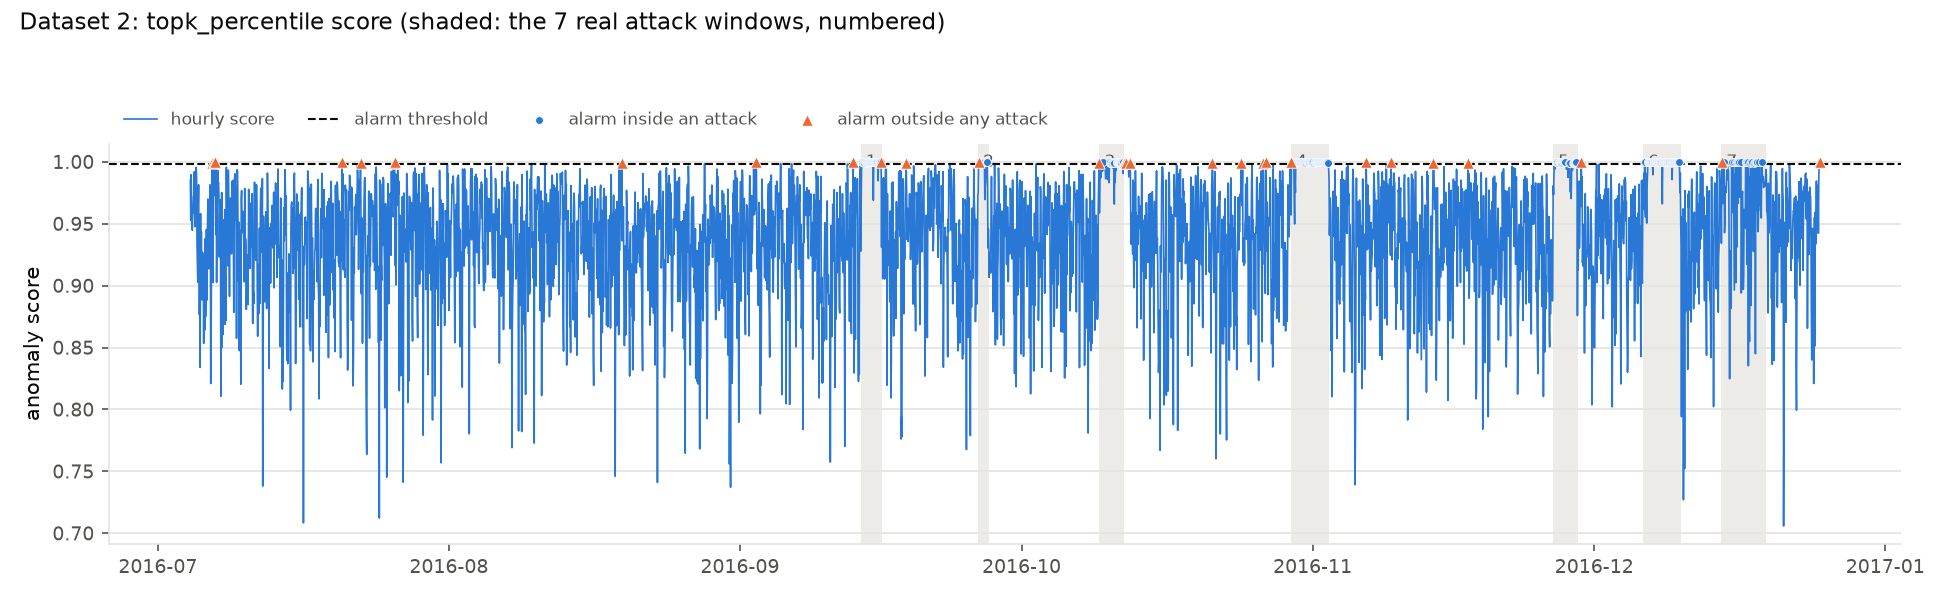

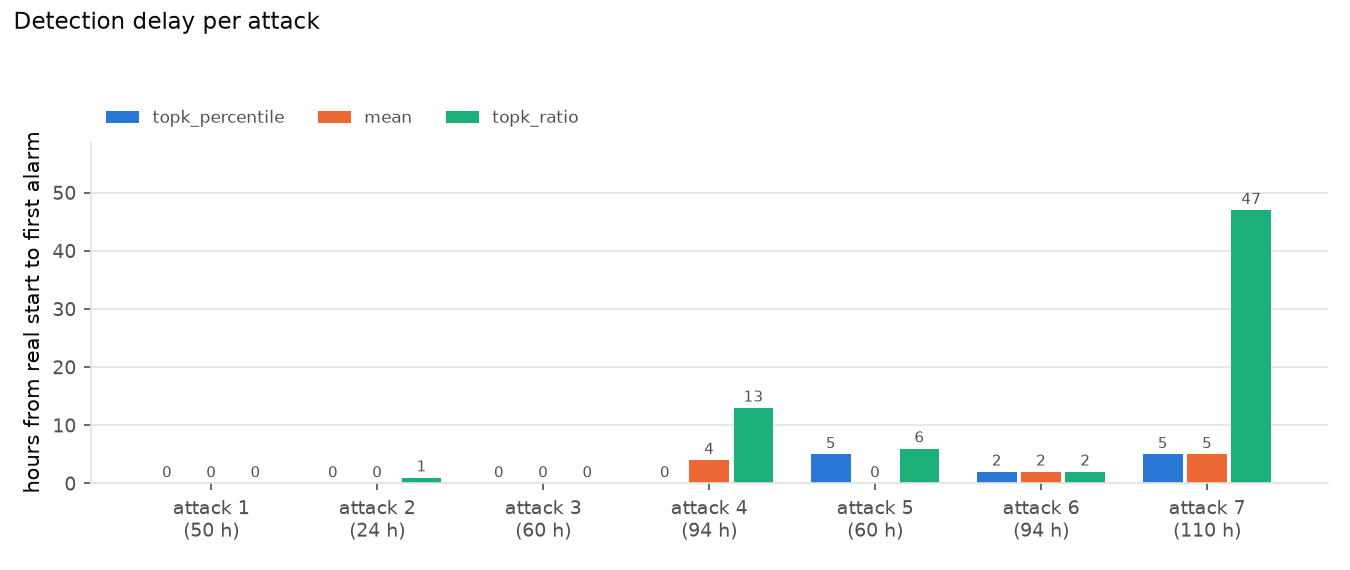

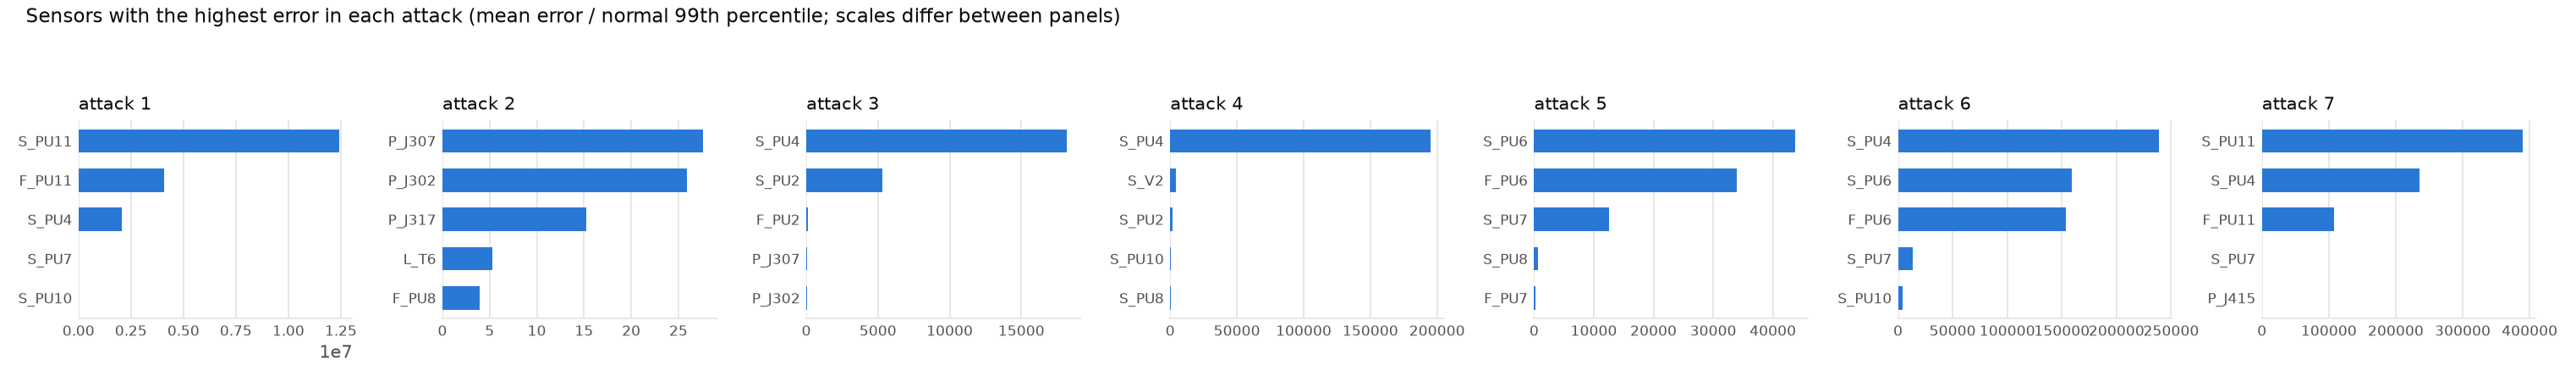

In [54]:
for name in [f"timeline_{SCORE}.png", "detection_delay.png", "top_sensors_per_attack.png"]:
    path = OUT_DIR / name
    if path.exists():
        display(Image(filename=str(path)))

### Save the summary

In [55]:
import json

summary = {
    "checkpoint": str(CHECKPOINT),
    "calibration": str(CALIBRATION),
    "score": SCORE,
    "window_hours": window,
    "grace_hours": GRACE_HOURS,
    "merge_gap_hours": merge_gap,
    "scored_hours": int(len(scores)),
    "attack_hours": int(is_attack.sum()),
    "clean_hours": int(is_clean.sum()),
    "true_positive_hours": tp, "false_negative_hours": fn,
    "false_positive_hours": fp, "true_negative_hours": tn,
    "false_alarm_episodes": int(len(false_summary)),
    **{key: (None if isinstance(value, float) and np.isnan(value) else value)
       for key, value in m.items() if not isinstance(value, (list, dict))}}
(OUT_DIR / "dataset2_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("Saved", OUT_DIR / "dataset2_summary.json", OUT_DIR / "attack_summary.csv", OUT_DIR / "false_alarm_summary.csv")

Saved inference_results/dataset2_summary.json inference_results/attack_summary.csv inference_results/false_alarm_summary.csv
